# 01 · First look

Load the raw file, check it's what the data dictionary says, and note anything odd before the real EDA (02).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from churn.data import download, load

path = download()
raw = pd.read_csv(path)
raw.shape

(7043, 21)

In [2]:
raw.dtypes.value_counts()

str        18
int64       2
float64     1
Name: count, dtype: int64

`TotalCharges` comes in as text (`str`), not a number. First thing to chase.

In [3]:
pd.to_numeric(raw["TotalCharges"], errors="coerce").isna().sum()

np.int64(11)

In [4]:
bad = raw[pd.to_numeric(raw["TotalCharges"], errors="coerce").isna()]
bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


All 11 have `tenure == 0`. They're new customers with no bill yet, so 0 is correct.

Dead end: I first tried `raw.isna().sum()` to find missing values and it said 0 everywhere. The blanks are a single space, not empty, so pandas doesn't count them as NaN.

In [5]:
raw.isna().sum().sum()

np.int64(0)

## After the loader's fixes

In [6]:
df = load()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   gender            7043 non-null   category
 1   SeniorCitizen     7043 non-null   int64   
 2   Partner           7043 non-null   category
 3   Dependents        7043 non-null   category
 4   tenure            7043 non-null   int64   
 5   PhoneService      7043 non-null   category
 6   MultipleLines     7043 non-null   category
 7   InternetService   7043 non-null   category
 8   OnlineSecurity    7043 non-null   category
 9   OnlineBackup      7043 non-null   category
 10  DeviceProtection  7043 non-null   category
 11  TechSupport       7043 non-null   category
 12  StreamingTV       7043 non-null   category
 13  StreamingMovies   7043 non-null   category
 14  Contract          7043 non-null   category
 15  PaperlessBilling  7043 non-null   category
 16  PaymentMethod     7043 non-null   c

In [7]:
df["Churn"].value_counts(normalize=True).round(3)

Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

About 26.5% churned. Not extreme imbalance, but accuracy alone would be misleading: predicting "no one churns" already scores 73.5%.

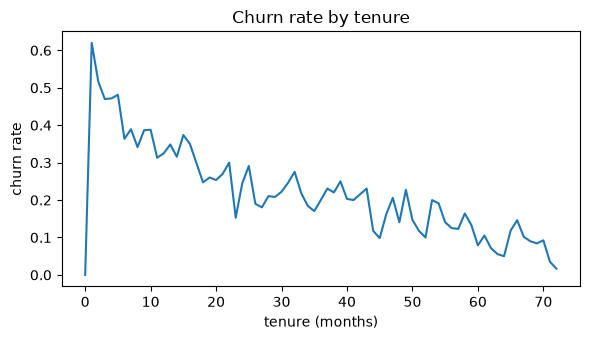

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
df.groupby("tenure")["Churn"].mean().plot(ax=ax)
ax.set(xlabel="tenure (months)", ylabel="churn rate", title="Churn rate by tenure")
fig.tight_layout()
fig.savefig("../reports/figures/churn_by_tenure.png", dpi=120)

Churn is highest in the first few months and falls steadily. Tenure will matter a lot.

## Notes for 02

- `TotalCharges` is mostly `tenure × MonthlyCharges` (correlation with tenure is 0.83). Watch for that in linear models.
- "No internet service" repeats across six columns: merge or keep?
- Look at contract type and payment method next.